In [1]:
# Step 1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings

warnings.filterwarnings("ignore")      # keeps the notebook output clean
sns.set_theme(style="whitegrid")       # nicer default chart style
pd.set_option("display.max_columns", None)  # show all columns when printing

# Change this to the real location of your file if it is not in the same folder
file_path = "supermarket_sales.csv"

df = pd.read_csv(file_path, encoding="utf-8-sig")

print("Libraries imported. Versions:")
print("  pandas      :", pd.__version__)
print("  numpy       :", np.__version__)
print("  scikit-learn:", sklearn.__version__)

print("\nDataset loaded successfully.")
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Libraries imported. Versions:
  pandas      : 2.3.3
  numpy       : 2.3.5
  scikit-learn: 1.9.1

Dataset loaded successfully.
Shape (rows, columns): (9994, 11)

Column names:
['Order ID', 'Customer Name', 'Category', 'Sub Category', 'City', 'Order Date', 'Region', 'Sales', 'Discount', 'Profit', 'State']


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,11-08-2017,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,06-12-2017,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,10-11-2016,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,10-11-2016,South,2355,0.26,918.45,Tamil Nadu


In [2]:
# Step 2: Understand the dataset and its columns

print("=== SHAPE ===")
print(df.shape)

print("\n=== INFO (data types and non-null counts) ===")
df.info()

print("\n=== DESCRIBE (numeric columns) ===")
display(df.describe())

print("\n=== MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())

print("\n=== DUPLICATE ROWS ===")
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated Order IDs :", df["Order ID"].duplicated().sum())

print("\n=== UNIQUE VALUES PER COLUMN ===")
print(df.nunique())

print("\n=== CATEGORICAL COLUMNS ===")
for col in ["Category", "Sub Category", "Region", "State"]:
    print(f"\n{col}:")
    print(df[col].value_counts())

print("\n=== SAMPLE OF ORDER DATE STRINGS ===")
print(df["Order Date"].sample(10, random_state=1).tolist())

=== SHAPE ===
(9994, 11)

=== INFO (data types and non-null counts) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   Category       9994 non-null   object 
 3   Sub Category   9994 non-null   object 
 4   City           9994 non-null   object 
 5   Order Date     9994 non-null   object 
 6   Region         9994 non-null   object 
 7   Sales          9994 non-null   int64  
 8   Discount       9994 non-null   float64
 9   Profit         9994 non-null   float64
 10  State          9994 non-null   object 
dtypes: float64(2), int64(1), object(8)
memory usage: 859.0+ KB

=== DESCRIBE (numeric columns) ===


,Sales,Discount,Profit
count,9994.000000,9994.000000,9994.000000
mean,1496.596158,0.226817,374.937082
std,577.559036,0.074636,239.932881
min,500.000000,0.100000,25.250000
25%,1000.000000,0.160000,180.022500
50%,1498.000000,0.230000,320.780000
75%,1994.750000,0.290000,525.627500
max,2500.000000,0.350000,1120.950000



=== MISSING VALUES PER COLUMN ===
Order ID         0
Customer Name    0
Category         0
Sub Category     0
City             0
Order Date       0
Region           0
Sales            0
Discount         0
Profit           0
State            0
dtype: int64

=== DUPLICATE ROWS ===
Fully duplicated rows: 0
Duplicated Order IDs : 0

=== UNIQUE VALUES PER COLUMN ===
Order ID         9994
Customer Name      50
Category            7
Sub Category       23
City               24
Order Date       1236
Region              5
Sales            1989
Discount           26
Profit           8380
State               1
dtype: int64

=== CATEGORICAL COLUMNS ===

Category:
Category
Snacks               1514
Eggs, Meat & Fish    1490
Fruits & Veggies     1418
Bakery               1413
Beverages            1400
Food Grains          1398
Oil & Masala         1361
Name: count, dtype: int64

Sub Category:
Sub Category
Health Drinks         719
Soft Drinks           681
Cookies               520
Breads & Buns    

In [3]:
# Step 3A: Diagnose Order Date formats and Region before cleaning

dates = df["Order Date"].astype(str).str.strip()

has_slash = dates.str.contains("/", regex=False)
has_dash = dates.str.contains("-", regex=False)

print("Rows with '/' dates     :", has_slash.sum())
print("Rows with '-' dates     :", has_dash.sum())
print("Rows with both / neither:", (has_slash & has_dash).sum(), "/", (~has_slash & ~has_dash).sum())

# --- Slash dates: split into 3 numeric parts ---
slash_parts = dates[has_slash].str.split("/", expand=True).astype(int)
print("\n=== SLASH dates (part 1 / part 2 / part 3) ===")
print("Part 1 min/max:", slash_parts[0].min(), slash_parts[0].max())
print("Part 2 min/max:", slash_parts[1].min(), slash_parts[1].max())
print("Part 3 min/max:", slash_parts[2].min(), slash_parts[2].max())

# --- Dash dates: split into 3 numeric parts ---
dash_parts = dates[has_dash].str.split("-", expand=True).astype(int)
print("\n=== DASH dates (part 1 - part 2 - part 3) ===")
print("Part 1 min/max:", dash_parts[0].min(), dash_parts[0].max())
print("Part 2 min/max:", dash_parts[1].min(), dash_parts[1].max())
print("Part 3 min/max:", dash_parts[2].min(), dash_parts[2].max())
print("Dash rows where part 1 > 12:", (dash_parts[0] > 12).sum())
print("Dash rows where part 2 > 12:", (dash_parts[1] > 12).sum())

# --- Region check ---
print("\n=== The single 'North' row ===")
display(df[df["Region"] == "North"])

print("\n=== City vs Region (row counts) ===")
display(pd.crosstab(df["City"], df["Region"]))

Rows with '/' dates     : 5952
Rows with '-' dates     : 4042
Rows with both / neither: 0 / 0

=== SLASH dates (part 1 / part 2 / part 3) ===
Part 1 min/max: 1 12
Part 2 min/max: 13 31
Part 3 min/max: 2015 2018

=== DASH dates (part 1 - part 2 - part 3) ===
Part 1 min/max: 1 12
Part 2 min/max: 1 12
Part 3 min/max: 2015 2018
Dash rows where part 1 > 12: 0
Dash rows where part 2 > 12: 0

=== The single 'North' row ===


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu



=== City vs Region (row counts) ===


Region,Central,East,North,South,West
City,,,,,
Bodi,99,116,0,63,164
Chennai,102,120,0,74,136
Coimbatore,114,114,0,77,123
Cumbum,85,136,0,75,121
Dharmapuri,83,102,0,52,139
Dindigul,103,103,0,59,131
Kanyakumari,111,142,0,74,132
Karur,98,126,0,69,137
Krishnagiri,118,120,0,78,124


In [4]:
# Step 3A-2: Decide how to read the dash-format dates

dates = df["Order Date"].astype(str).str.strip()
has_slash = dates.str.contains("/", regex=False)

# Slash dates: month is part 1 (certain, because part 2 goes up to 31)
slash_month = dates[has_slash].str.split("/", expand=True)[0].astype(int)

# Dash dates: split into the two ambiguous parts
dash = dates[~has_slash].str.split("-", expand=True).astype(int)

# Compare month distribution: slash months vs each possible month column in dash dates
comparison = pd.DataFrame({
    "slash_month_%": slash_month.value_counts(normalize=True).sort_index() * 100,
    "dash_part1_%":  dash[0].value_counts(normalize=True).sort_index() * 100,
    "dash_part2_%":  dash[1].value_counts(normalize=True).sort_index() * 100,
}).round(1)

print("=== Share of rows per month number (1-12), in % ===")
display(comparison)

# Parse the dash dates both ways and compare the resulting date ranges
dash_strings = dates[~has_slash]
as_month_first = pd.to_datetime(dash_strings, format="%m-%d-%Y")
as_day_first   = pd.to_datetime(dash_strings, format="%d-%m-%Y")

print("\nIf dash = month-day-year -> range:", as_month_first.min().date(), "to", as_month_first.max().date())
print("If dash = day-month-year -> range:", as_day_first.min().date(), "to", as_day_first.max().date())

slash_dates = pd.to_datetime(dates[has_slash], format="%m/%d/%Y")
print("Slash dates (month/day/year)     -> range:", slash_dates.min().date(), "to", slash_dates.max().date())

=== Share of rows per month number (1-12), in % ===


,slash_month_%,dash_part1_%,dash_part2_%
1,4.4,3.0,8.3
2,2.8,3.2,9.4
3,7.6,6.0,9.0
4,6.5,6.9,7.6
5,7.7,6.8,9.1
6,7.1,7.3,7.1
7,7.4,6.6,7.4
8,7.7,6.1,8.8
9,13.3,14.6,8.5
10,8.5,7.7,7.4



If dash = month-day-year -> range: 2015-01-03 to 2018-12-11
If dash = day-month-year -> range: 2015-01-02 to 2018-12-11
Slash dates (month/day/year)     -> range: 2015-01-13 to 2018-12-30


## Step 3B: Data cleaning
- Convert Order Date to datetime (slash = %m/%d/%Y, dash = %m-%d-%Y)
- Drop the constant State column
- Validate Sales, Discount, Profit
- Sort chronologically## Step 3B: Data cleaning
- Convert Order Date to datetime (slash = %m/%d/%Y, dash = %m-%d-%Y)
- Drop the constant State column
- Validate Sales, Discount, Profit
- Sort chronologically

In [5]:
# Step 3B: Data cleaning

df_clean = df.copy()   # work on a copy so the raw data stays untouched

# 1. Remove accidental spaces in text columns
text_cols = ["Order ID", "Customer Name", "Category", "Sub Category", "City", "Region"]
for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 2. Convert Order Date: each format is parsed with its own explicit format
dates = df_clean["Order Date"].astype(str).str.strip()
is_slash = dates.str.contains("/", regex=False)

parsed_slash = pd.to_datetime(dates[is_slash], format="%m/%d/%Y")
parsed_dash = pd.to_datetime(dates[~is_slash], format="%m-%d-%Y")

df_clean["Order Date"] = pd.concat([parsed_slash, parsed_dash]).sort_index()

# 3. Drop State (only one value, so it carries no information)
df_clean = df_clean.drop(columns=["State"])

# 4. Remove exact duplicate rows (we found 0 earlier, this is a safety check)
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicate rows removed:", before - len(df_clean))

# 5. Sort chronologically
df_clean = df_clean.sort_values("Order Date").reset_index(drop=True)

# 6. Validation checks
print("\n=== VALIDATION ===")
print("Missing dates          :", df_clean["Order Date"].isnull().sum())
print("Sales <= 0             :", (df_clean["Sales"] <= 0).sum())
print("Discount outside 0-1   :", ((df_clean["Discount"] < 0) | (df_clean["Discount"] > 1)).sum())
print("Profit <= 0            :", (df_clean["Profit"] <= 0).sum())
print("Date range             :", df_clean["Order Date"].min().date(), "to", df_clean["Order Date"].max().date())
print("Unique order dates     :", df_clean["Order Date"].nunique())

print("\n=== ORDERS PER YEAR ===")
print(df_clean["Order Date"].dt.year.value_counts().sort_index())

print("\n=== DATA TYPES AFTER CLEANING ===")
print(df_clean.dtypes)

print("\nRegion counts (note the 1-row 'North' group):")
print(df_clean["Region"].value_counts())

df_clean.head()

Duplicate rows removed: 0

=== VALIDATION ===
Missing dates          : 0
Sales <= 0             : 0
Discount outside 0-1   : 0
Profit <= 0            : 0
Date range             : 2015-01-03 to 2018-12-30
Unique order dates     : 1236

=== ORDERS PER YEAR ===
Order Date
2015    1993
2016    2102
2017    2587
2018    3312
Name: count, dtype: int64

=== DATA TYPES AFTER CLEANING ===
Order ID                 object
Customer Name            object
Category                 object
Sub Category             object
City                     object
Order Date       datetime64[ns]
Region                   object
Sales                     int64
Discount                float64
Profit                  float64
dtype: object

Region counts (note the 1-row 'North' group):
Region
West       3203
East       2848
Central    2323
South      1619
North         1
Name: count, dtype: int64


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit
0,OD3324,Jackson,Bakery,Breads & Buns,Salem,2015-01-03,Central,864,0.26,380.16
1,OD740,Haseena,Bakery,Cakes,Nagercoil,2015-01-04,Central,2033,0.15,325.28
2,OD741,Vinne,Beverages,Health Drinks,Trichy,2015-01-04,Central,698,0.32,223.36
3,OD742,Sudha,Snacks,Chocolates,Dharmapuri,2015-01-04,Central,759,0.27,174.57
4,OD3873,Verma,"Eggs, Meat & Fish",Fish,Tirunelveli,2015-01-05,East,878,0.35,149.26


## Step 4: Exploratory Data Analysis (EDA)
- Total sales, profit, orders
- Sales by Category, Sub Category (product proxy), Region
- Top sub-categories
- Sales distribution

In [6]:
# Step 4A: Totals and group summaries

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
n_orders = len(df_clean)

print("Total sales      :", f"{total_sales:,}")
print("Total profit     :", f"{total_profit:,.2f}")
print("Number of orders :", f"{n_orders:,}")
print("Average order    :", f"{df_clean['Sales'].mean():,.2f}")
print("Profit / Sales   :", f"{total_profit / total_sales:.1%}")
print("NOTE: no Quantity column exists, so 'quantity sold' = number of orders.")

def summarize(by):
    out = (df_clean.groupby(by)
           .agg(total_sales=("Sales", "sum"),
                orders=("Sales", "count"),
                avg_order=("Sales", "mean"),
                total_profit=("Profit", "sum"))
           .sort_values("total_sales", ascending=False))
    out["sales_share_%"] = (out["total_sales"] / total_sales * 100).round(1)
    return out.round(1)

print("\n=== BY CATEGORY ===")
display(summarize("Category"))

print("\n=== BY REGION (North has only 1 order) ===")
display(summarize("Region"))

print("\n=== TOP 10 SUB CATEGORIES BY SALES ===")
display(summarize("Sub Category").head(10))

print("\n=== BOTTOM 5 SUB CATEGORIES BY SALES ===")
display(summarize("Sub Category").tail(5))

Total sales      : 14,956,982
Total profit     : 3,747,121.20
Number of orders : 9,994
Average order    : 1,496.60
Profit / Sales   : 25.1%
NOTE: no Quantity column exists, so 'quantity sold' = number of orders.

=== BY CATEGORY ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Category,,,,,
"Eggs, Meat & Fish",2267401,1490,1521.7,567357.2,15.2
Snacks,2237546,1514,1477.9,568178.8,15.0
Food Grains,2115272,1398,1513.1,529162.6,14.1
Bakery,2112281,1413,1494.9,528521.1,14.1
Fruits & Veggies,2100727,1418,1481.5,530400.4,14.0
Beverages,2085313,1400,1489.5,525605.8,13.9
Oil & Masala,2038442,1361,1497.8,497895.3,13.6



=== BY REGION (North has only 1 order) ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Region,,,,,
West,4798743,3203,1498.2,1192004.6,32.1
East,4248368,2848,1491.7,1074345.6,28.4
Central,3468156,2323,1493.0,856806.8,23.2
South,2440461,1619,1507.4,623562.9,16.3
North,1254,1,1254.0,401.3,0.0



=== TOP 10 SUB CATEGORIES BY SALES ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Sub Category,,,,,
Health Drinks,1051439,719,1462.4,267469.8,7.0
Soft Drinks,1033874,681,1518.2,258136.0,6.9
Cookies,768213,520,1477.3,190643.7,5.1
Breads & Buns,742586,502,1479.3,190765.0,5.0
Noodles,735435,495,1485.7,193685.8,4.9
Chocolates,733898,499,1470.7,183849.3,4.9
Masalas,697480,463,1506.4,168999.1,4.7
Cakes,685612,452,1516.8,168398.5,4.6
Biscuits,684083,459,1490.4,169357.6,4.6



=== BOTTOM 5 SUB CATEGORIES BY SALES ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Sub Category,,,,,
Dals & Pulses,523371,343,1525.9,130232.3,3.5
Chicken,520497,348,1495.7,124049.9,3.5
Organic Vegetables,520271,347,1499.3,133596.4,3.5
Organic Fruits,503402,348,1446.6,130862.3,3.4
Rice,498323,330,1510.1,126932.4,3.3


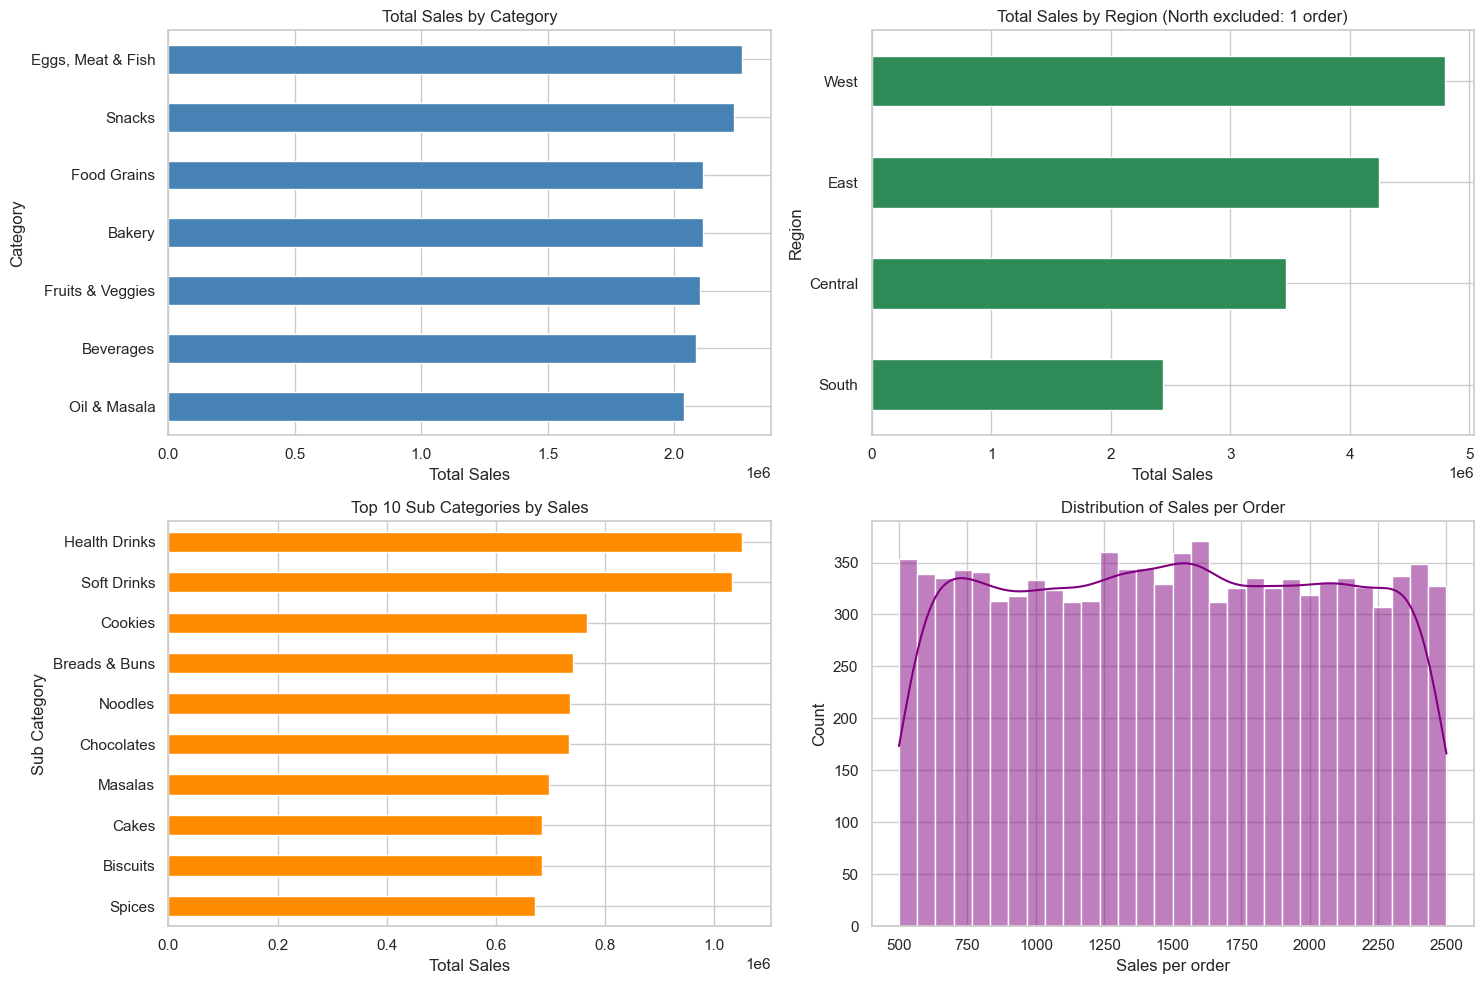

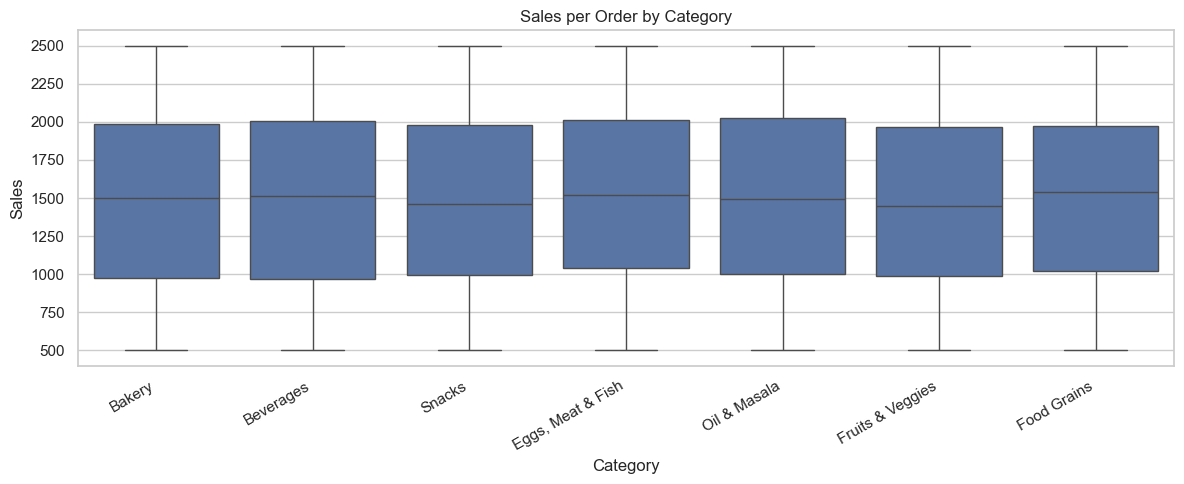

In [7]:
# Step 4B: Visualizations

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Sales by Category
cat = df_clean.groupby("Category")["Sales"].sum().sort_values()
cat.plot(kind="barh", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Total Sales by Category")
axes[0, 0].set_xlabel("Total Sales")

# 2. Sales by Region (North excluded from the chart, see title)
reg = (df_clean[df_clean["Region"] != "North"]
       .groupby("Region")["Sales"].sum().sort_values())
reg.plot(kind="barh", ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title("Total Sales by Region (North excluded: 1 order)")
axes[0, 1].set_xlabel("Total Sales")

# 3. Top 10 sub categories
sub = df_clean.groupby("Sub Category")["Sales"].sum().sort_values().tail(10)
sub.plot(kind="barh", ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("Top 10 Sub Categories by Sales")
axes[1, 0].set_xlabel("Total Sales")

# 4. Distribution of order value
sns.histplot(df_clean["Sales"], bins=30, kde=True, ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Distribution of Sales per Order")
axes[1, 1].set_xlabel("Sales per order")

plt.tight_layout()
plt.show()

# Box plot of sales by category, to compare order values
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_clean, x="Category", y="Sales")
plt.xticks(rotation=30, ha="right")
plt.title("Sales per Order by Category")
plt.tight_layout()
plt.show()

## Step 5: Time-series analysis
- Daily, monthly, quarterly, and yearly aggregation
- Separate order count from average order value
- Seasonality by month
- Unusually high or low periods

In [8]:
# Step 5A: Aggregate sales over time

ts = df_clean.set_index("Order Date")

# Daily totals, including days with no orders
daily = ts["Sales"].resample("D").sum()
daily_orders = ts["Sales"].resample("D").count()

print("Total calendar days in range :", len(daily))
print("Days with at least 1 order   :", (daily_orders > 0).sum())
print("Days with NO orders          :", (daily_orders == 0).sum())

# Monthly: sales, orders, and average order value
monthly = ts.resample("MS").agg(sales=("Sales", "sum"),
                                orders=("Sales", "count"),
                                avg_order=("Sales", "mean"))
monthly["avg_order"] = monthly["avg_order"].round(1)

print("\nNumber of months:", len(monthly))
display(monthly.head(12))

# Yearly summary
yearly = df_clean.groupby(df_clean["Order Date"].dt.year).agg(
    sales=("Sales", "sum"),
    orders=("Sales", "count"),
    avg_order=("Sales", "mean"))
yearly["sales_growth_%"] = (yearly["sales"].pct_change() * 100).round(1)
yearly["orders_growth_%"] = (yearly["orders"].pct_change() * 100).round(1)
yearly["avg_order"] = yearly["avg_order"].round(1)
print("\n=== YEARLY ===")
display(yearly)

# Quarterly summary
quarterly = ts["Sales"].resample("QS").sum()
print("\n=== QUARTERLY SALES ===")
display(quarterly)

Total calendar days in range : 1458
Days with at least 1 order   : 1236
Days with NO orders          : 222

Number of months: 48


,sales,orders,avg_order
Order Date,,,
2015-01-01,122497,79,1550.6
2015-02-01,66030,46,1435.4
2015-03-01,247156,157,1574.2
2015-04-01,203258,135,1505.6
2015-05-01,164263,122,1346.4
2015-06-01,206064,135,1526.4
2015-07-01,220986,143,1545.4
2015-08-01,230161,153,1504.3
2015-09-01,382200,268,1426.1



=== YEARLY ===


,sales,orders,avg_order,sales_growth_%,orders_growth_%
Order Date,,,,,
2015,2975599,1993,1493.0,NaN,NaN
2016,3131959,2102,1490.0,5.3,5.5
2017,3871912,2587,1496.7,23.6,23.1
2018,4977512,3312,1502.9,28.6,28.0



=== QUARTERLY SALES ===


Order Date
2015-01-01     435683
2015-04-01     573585
2015-07-01     833347
2015-10-01    1132984
2016-01-01     391996
2016-04-01     665382
2016-07-01     874977
2016-10-01    1199604
2017-01-01     503665
2017-04-01     871751
2017-07-01    1118348
2017-10-01    1378148
2018-01-01     756710
2018-04-01    1032463
2018-07-01    1373786
2018-10-01    1814553
Freq: QS-JAN, Name: Sales, dtype: int64

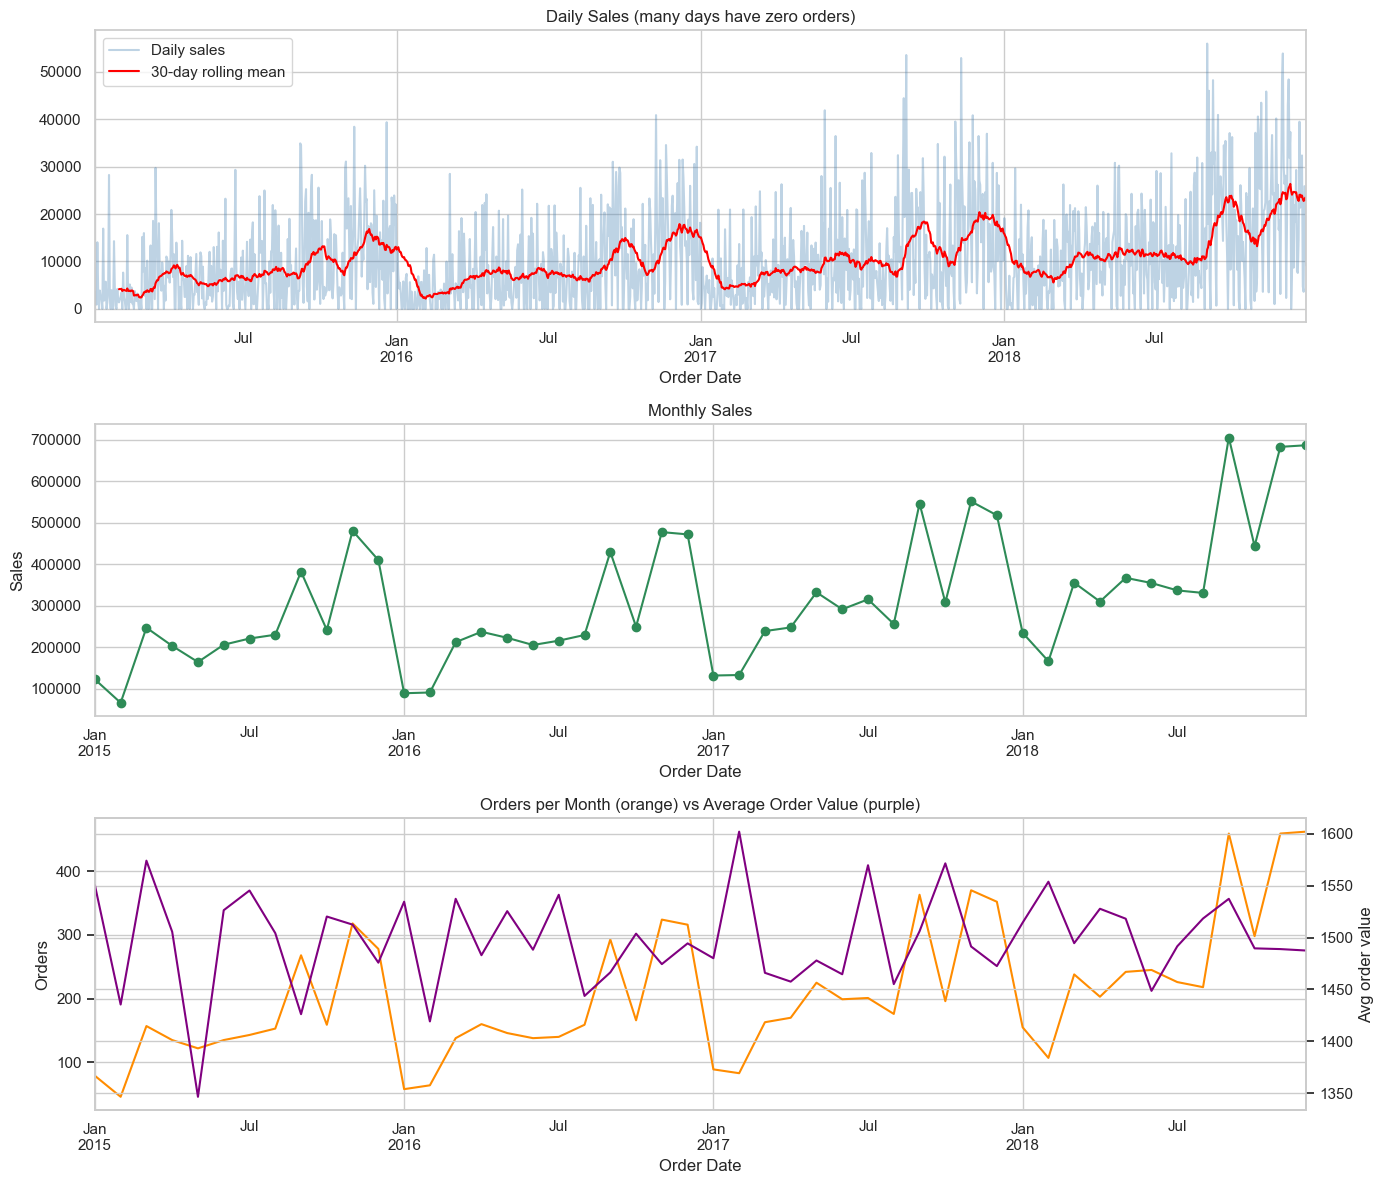

In [9]:
# Step 5B: Plot historical trends

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Daily with 30-day rolling mean
daily.plot(ax=axes[0], alpha=0.35, color="steelblue", label="Daily sales")
daily.rolling(30).mean().plot(ax=axes[0], color="red", label="30-day rolling mean")
axes[0].set_title("Daily Sales (many days have zero orders)")
axes[0].legend()

# Monthly sales
monthly["sales"].plot(ax=axes[1], marker="o", color="seagreen")
axes[1].set_title("Monthly Sales")
axes[1].set_ylabel("Sales")

# Monthly order count vs average order value
ax2 = axes[2]
monthly["orders"].plot(ax=ax2, color="darkorange", label="Orders per month")
ax2.set_ylabel("Orders")
ax3 = ax2.twinx()
monthly["avg_order"].plot(ax=ax3, color="purple", label="Avg order value")
ax3.set_ylabel("Avg order value")
ax2.set_title("Orders per Month (orange) vs Average Order Value (purple)")

plt.tight_layout()
plt.show()

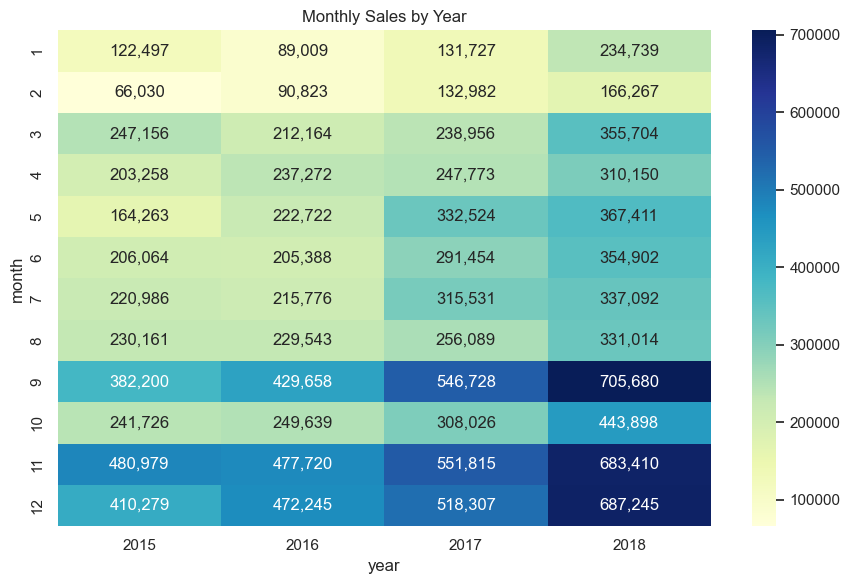

=== Each month's share of that year's sales (%) ===


year,2015,2016,2017,2018,avg_share_%
month,,,,,
1,4.1,2.8,3.4,4.7,3.8
2,2.2,2.9,3.4,3.3,3.0
3,8.3,6.8,6.2,7.1,7.1
4,6.8,7.6,6.4,6.2,6.7
5,5.5,7.1,8.6,7.4,7.2
6,6.9,6.6,7.5,7.1,7.0
7,7.4,6.9,8.1,6.8,7.3
8,7.7,7.3,6.6,6.7,7.1
9,12.8,13.7,14.1,14.2,13.7



=== Months with |z| > 2 (relative to local 12-month level) ===


,sales,orders,z
Order Date,,,


In [10]:
# Step 5C: Seasonality and unusual months

monthly_c = monthly.copy()
monthly_c["year"] = monthly_c.index.year
monthly_c["month"] = monthly_c.index.month

# Month x Year heatmap of sales
pivot = monthly_c.pivot(index="month", columns="year", values="sales")
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu")
plt.title("Monthly Sales by Year")
plt.tight_layout()
plt.show()

# Average share of each year's sales that falls in each month
share = (pivot / pivot.sum() * 100).round(1)
share["avg_share_%"] = share.mean(axis=1).round(1)
print("=== Each month's share of that year's sales (%) ===")
display(share)

# Unusual months: more than 2 standard deviations from a 12-month rolling mean
roll_mean = monthly["sales"].rolling(12, center=True, min_periods=6).mean()
roll_std = monthly["sales"].rolling(12, center=True, min_periods=6).std()
z = (monthly["sales"] - roll_mean) / roll_std
print("\n=== Months with |z| > 2 (relative to local 12-month level) ===")
display(monthly.loc[z.abs() > 2, ["sales", "orders"]].assign(z=z[z.abs() > 2].round(2)))

## Step 6A: Choose the forecast frequency
- Compare daily, weekly, and monthly aggregation
- Check where the zero-order days fall
- Decide the target series

,periods,periods_with_zero_orders,avg_orders_per_period,min_sales,median_sales,max_sales
frequency,,,,,,
Daily,1458,222,6.9,0,7705.5,55976
Weekly,208,0,48.0,8968,64019.5,196342
Monthly,48,0,208.2,66030,252864.0,705680


Zero-order days by calendar month (1 = January):
Order Date
1     38
2     33
3     18
4     18
5     13
6     20
7     22
8     23
9     11
10    14
11     4
12     8
Name: count, dtype: int64


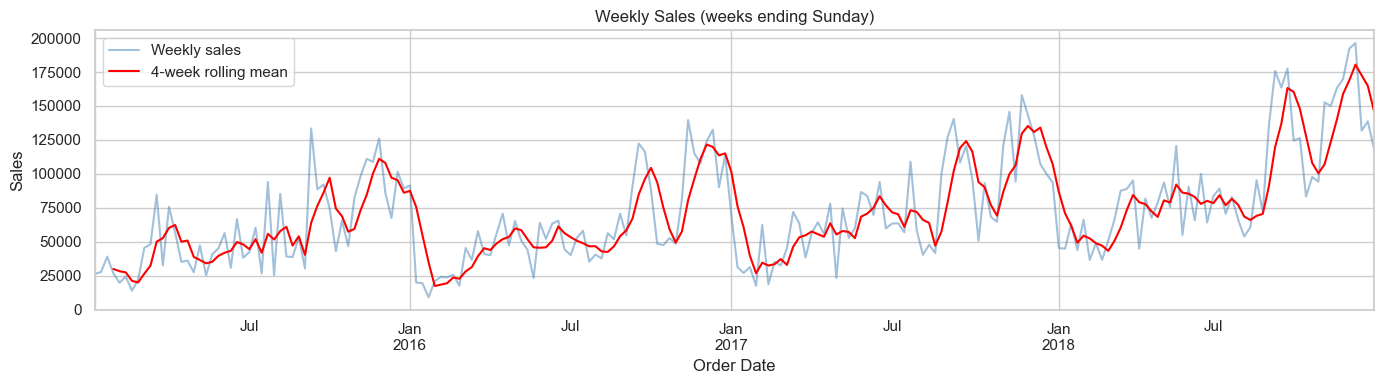

Weekly range: 2015-01-11 to 2018-12-30


In [11]:
# Step 6A: Compare daily, weekly and monthly aggregation

ts = df_clean.set_index("Order Date")

# Build sales and order counts at three frequencies
agg = {}
for name, rule in [("Daily", "D"), ("Weekly", "W-SUN"), ("Monthly", "MS")]:
    r = ts["Sales"].resample(rule).agg(["sum", "count"])
    if name == "Weekly":
        r = r.iloc[1:]   # drop the first week: data starts on a Saturday, so it is only 2 days long
    agg[name] = r

# Summary comparison
rows = []
for name, r in agg.items():
    rows.append({
        "frequency": name,
        "periods": len(r),
        "periods_with_zero_orders": int((r["count"] == 0).sum()),
        "avg_orders_per_period": round(r["count"].mean(), 1),
        "min_sales": r["sum"].min(),
        "median_sales": r["sum"].median(),
        "max_sales": r["sum"].max(),
    })
display(pd.DataFrame(rows).set_index("frequency"))

# Where do the zero-order days fall?
daily_counts = agg["Daily"]["count"]
zero_days = daily_counts[daily_counts == 0]
print("Zero-order days by calendar month (1 = January):")
print(zero_days.groupby(zero_days.index.month).size())

# Plot the weekly series
weekly_sales = agg["Weekly"]["sum"]
plt.figure(figsize=(14, 4))
weekly_sales.plot(alpha=0.5, color="steelblue", label="Weekly sales")
weekly_sales.rolling(4).mean().plot(color="red", label="4-week rolling mean")
plt.title("Weekly Sales (weeks ending Sunday)")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

print("Weekly range:", weekly_sales.index.min().date(), "to", weekly_sales.index.max().date())

## Step 6B: Build the weekly dataset, features and chronological split
- Weekly total sales as the target
- Calendar features, lag features, rolling mean (past information only)
- Chronological split: last 26 weeks as the test set

In [12]:
# Step 6B: Weekly dataset, features, and chronological split

# 1. Weekly target (weeks ending Sunday; first partial week dropped)
ts = df_clean.set_index("Order Date")
weekly_sales = ts["Sales"].resample("W-SUN").sum().iloc[1:]

data = pd.DataFrame({"sales": weekly_sales})
data.index.name = "week_end"

# 2. Calendar features (known in advance, no leakage possible)
data["t"] = np.arange(len(data))                       # time index: 0, 1, 2, ...
doy = data.index.dayofyear
data["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
data["season_cos"] = np.cos(2 * np.pi * doy / 365.25)

# 3. Lag features: shift(k) moves values DOWN k rows, so each row sees only the past
for k in [1, 2, 4, 52]:
    data[f"lag_{k}"] = data["sales"].shift(k)

# 4. Rolling mean of the previous 4 weeks (shift(1) first, so the current week is excluded)
data["roll_mean_4"] = data["sales"].shift(1).rolling(4).mean()

# 5. Leakage checks
assert np.isclose(data["lag_1"].iloc[5], data["sales"].iloc[4])
assert np.isclose(data["roll_mean_4"].iloc[10], data["sales"].iloc[6:10].mean())
print("Leakage checks passed.")

# 6. Drop rows where lags are not available yet (the first 52 weeks)
model_df = data.dropna().copy()
print("Weekly rows before / after dropna:", len(data), "/", len(model_df))

# 7. Chronological split (no shuffling)
test_weeks = 26
train = model_df.iloc[:-test_weeks]
test = model_df.iloc[-test_weeks:]

target = "sales"
feature_cols = [c for c in model_df.columns if c != target]

X_train, y_train = train[feature_cols], train[target]
X_test, y_test = test[feature_cols], test[target]

print("\nFeatures:", feature_cols)
print("Train:", X_train.shape, train.index.min().date(), "to", train.index.max().date())
print("Test :", X_test.shape, test.index.min().date(), "to", test.index.max().date())
print("Train ends before test starts:", train.index.max() < test.index.min())

print("\nTrain sales  min / max:", y_train.min(), "/", y_train.max())
print("Test sales   min / max:", y_test.min(), "/", y_test.max())

display(model_df.head())

Leakage checks passed.
Weekly rows before / after dropna: 208 / 156

Features: ['t', 'season_sin', 'season_cos', 'lag_1', 'lag_2', 'lag_4', 'lag_52', 'roll_mean_4']
Train: (130, 8) 2016-01-10 to 2018-07-01
Test : (26, 8) 2018-07-08 to 2018-12-30
Train ends before test starts: True

Train sales  min / max: 8968 / 157948
Test sales   min / max: 53816 / 196342


,sales,t,season_sin,season_cos,lag_1,lag_2,lag_4,lag_52,roll_mean_4
week_end,,,,,,,,,
2016-01-10,19886,52,0.171177,0.985240,91438.0,89259.0,67370.0,26376.0,87376.75
2016-01-17,19457,53,0.288291,0.957543,19886.0,91438.0,101440.0,27580.0,75505.75
2016-01-24,8968,54,0.401229,0.915978,19457.0,19886.0,89259.0,38995.0,55010.00
2016-01-31,20918,55,0.508356,0.861147,8968.0,19457.0,91438.0,26530.0,34937.25
2016-02-07,24035,56,0.608121,0.793844,20918.0,8968.0,19886.0,19737.0,17307.25


Growth factor range on test weeks: 1.194 to 1.287

=== BASELINE RESULTS (test set, 26 weeks) ===


,MAE,RMSE,R2,MAPE_%
model,,,,
Naive (last week),22118,29373,0.526,19.7
Moving average (4 weeks),33838,39037,0.162,27.6
Seasonal naive (lag_52),32064,37901,0.210,26.3
Seasonal naive x growth,22039,28728,0.546,19.4


Mean weekly sales in test set: 122412


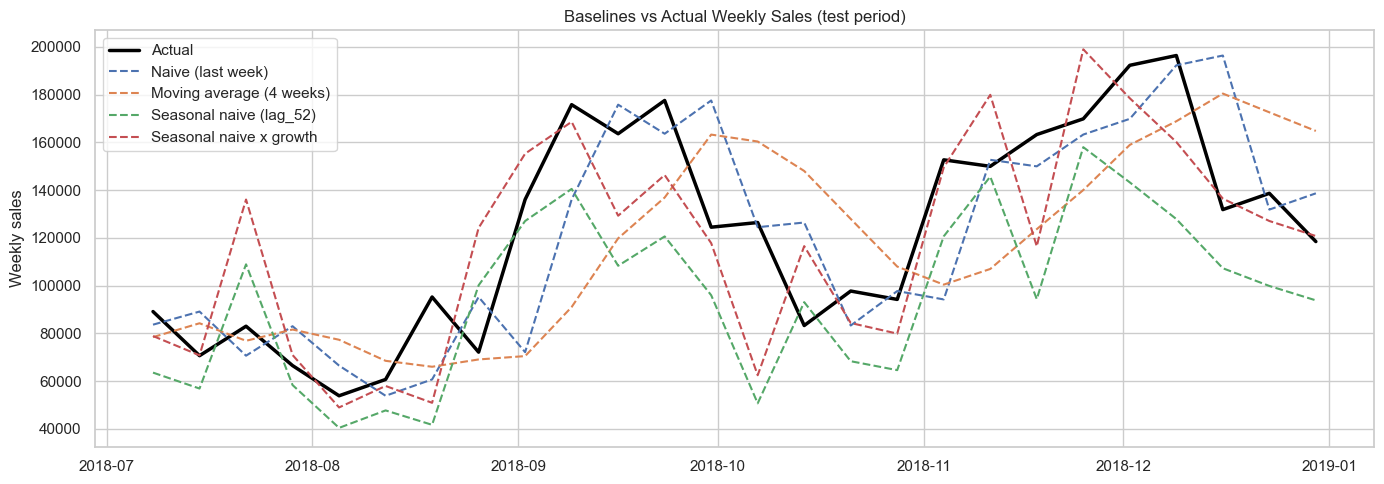

In [14]:
# Step 7: Baseline models

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Reusable evaluation function
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # MAPE divides by actual sales, so it is only safe if no actual value is zero
    assert (y_true > 0).all(), "Zero actual sales found: MAPE would be invalid"
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"model": name, "MAE": round(mae), "RMSE": round(rmse),
            "R2": round(r2, 3), "MAPE_%": round(mape, 1)}

# 2. Growth factor using only past data (rolling 52-week sums, shifted)
sum_last_52 = data["sales"].rolling(52).sum().shift(1)    # weeks t-52 ... t-1
sum_prev_52 = data["sales"].rolling(52).sum().shift(53)   # weeks t-104 ... t-53
growth = (sum_last_52 / sum_prev_52).reindex(X_test.index)
print(f"Growth factor range on test weeks: {growth.min():.3f} to {growth.max():.3f}")
assert growth.notna().all()

# 3. Baseline predictions on the test set
baseline_preds = pd.DataFrame({
    "Naive (last week)":           X_test["lag_1"],
    "Moving average (4 weeks)":    X_test["roll_mean_4"],
    "Seasonal naive (lag_52)":     X_test["lag_52"],
    "Seasonal naive x growth":     X_test["lag_52"] * growth,
})

results = [evaluate(y_test, baseline_preds[c], c) for c in baseline_preds.columns]
baseline_results = pd.DataFrame(results).set_index("model")
print("\n=== BASELINE RESULTS (test set, 26 weeks) ===")
display(baseline_results)

print("Mean weekly sales in test set:", round(y_test.mean()))

# 4. Plot actual vs baselines
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, color="black", linewidth=2.5, label="Actual")
for c in baseline_preds.columns:
    plt.plot(baseline_preds.index, baseline_preds[c], linestyle="--", label=c)
plt.title("Baselines vs Actual Weekly Sales (test period)")
plt.ylabel("Weekly sales")
plt.legend()
plt.tight_layout()
plt.show()

## Step 8: Train Linear Regression and Random Forest
- Fit on the training set only
- Compare against the baselines on the same 26 test weeks
- Check bias and the training-range limit

=== ALL MODELS (test set, 26 weeks, one-step-ahead) ===


,MAE,RMSE,R2,MAPE_%
model,,,,
Linear Regression,20300,24172,0.679,18.5
Seasonal naive x growth,22039,28728,0.546,19.4
Naive (last week),22118,29373,0.526,19.7
Random Forest,28647,34051,0.363,23.1
Seasonal naive (lag_52),32064,37901,0.210,26.3
Moving average (4 weeks),33838,39037,0.162,27.6



=== AVERAGE ERROR (prediction - actual) ===
Linear Regression   : -6,222
Random Forest       : -17,352
Seasonal naive x gr.: -4,490

Training max sales            : 157948
Test max sales                : 196342
Random Forest max prediction  : 130018
Linear Reg. max prediction    : 161588

=== LINEAR REGRESSION COEFFICIENTS ===
t               203.618
season_sin    -7187.701
season_cos      517.704
lag_1             0.250
lag_2             0.238
lag_4            -0.087
lag_52            0.477
roll_mean_4      -0.247
dtype: float64

=== RANDOM FOREST FEATURE IMPORTANCE ===
lag_52         0.439
lag_1          0.162
t              0.121
lag_2          0.082
season_cos     0.070
season_sin     0.064
lag_4          0.031
roll_mean_4    0.030
dtype: float64


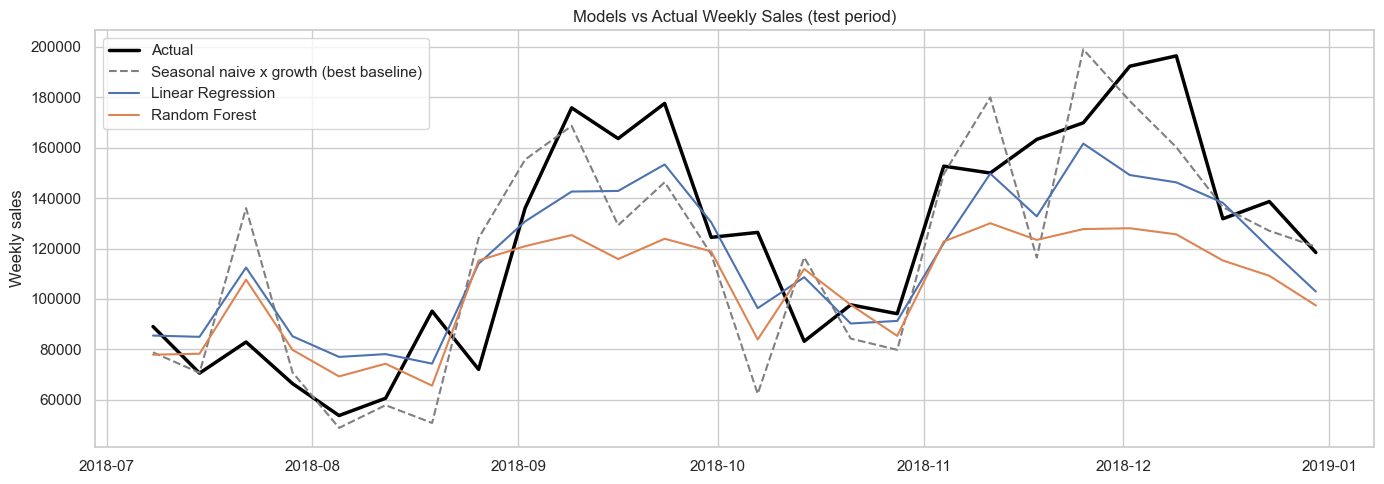

In [15]:
# Step 8: Train models and compare with baselines

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Define the models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42),
}

# 2. Fit on training data only, predict on test data
model_preds = {}
ml_results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = pd.Series(model.predict(X_test), index=X_test.index)
    model_preds[name] = pred
    ml_results.append(evaluate(y_test, pred, name))

ml_results = pd.DataFrame(ml_results).set_index("model")

# 3. Compare with baselines
comparison = pd.concat([baseline_results, ml_results])
print("=== ALL MODELS (test set, 26 weeks, one-step-ahead) ===")
display(comparison.sort_values("MAE"))

# 4. Bias check: average (prediction - actual). Negative = under-predicts.
print("\n=== AVERAGE ERROR (prediction - actual) ===")
for name, pred in model_preds.items():
    print(f"{name:20s}: {(pred - y_test).mean():,.0f}")
best_base = baseline_preds["Seasonal naive x growth"]
print(f"{'Seasonal naive x gr.':20s}: {(best_base - y_test).mean():,.0f}")

# 5. Training-range check for the tree model
print("\nTraining max sales            :", y_train.max())
print("Test max sales                :", y_test.max())
print("Random Forest max prediction  :", round(model_preds["Random Forest"].max()))
print("Linear Reg. max prediction    :", round(model_preds["Linear Regression"].max()))

# 6. What did the models learn?
print("\n=== LINEAR REGRESSION COEFFICIENTS ===")
print(pd.Series(models["Linear Regression"].coef_, index=feature_cols).round(3))
print("\n=== RANDOM FOREST FEATURE IMPORTANCE ===")
print(pd.Series(models["Random Forest"].feature_importances_,
                index=feature_cols).sort_values(ascending=False).round(3))

# 7. Plot
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, color="black", linewidth=2.5, label="Actual")
plt.plot(best_base.index, best_base, "--", color="gray", label="Seasonal naive x growth (best baseline)")
for name, pred in model_preds.items():
    plt.plot(pred.index, pred, label=name)
plt.title("Models vs Actual Weekly Sales (test period)")
plt.ylabel("Weekly sales")
plt.legend()
plt.tight_layout()
plt.show()

## Step 9: Detailed model evaluation
- Error by month and residuals for Linear Regression
- Walk-forward validation to check the result is not a one-window accident
- MAPE limitation check

=== LINEAR REGRESSION ERROR BY MONTH (positive % = under-predicted) ===


,weeks,mean_actual,MAE,mean_pct_error
week_end,,,,
7,4,77277.2,16567.6,-20.0
8,4,70435.8,25859.6,-27.1
9,5,155463.6,17882.0,8.9
10,4,100371.5,16417.9,1.0
11,4,158909.8,17374.9,10.9
12,5,155485.6,26699.6,13.9


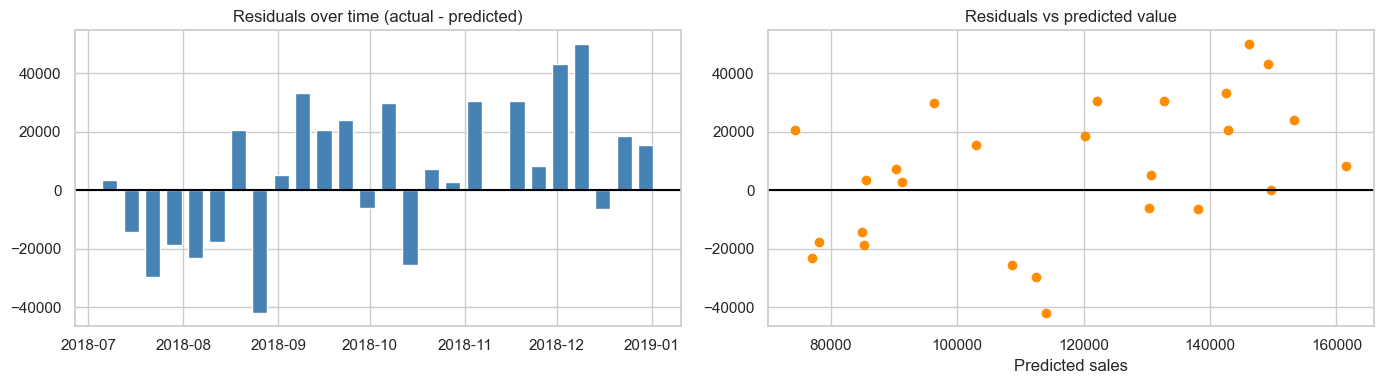


=== WALK-FORWARD VALIDATION (MAE, lower is better) ===


,test_window,train_weeks,LinReg_MAE,Baseline_MAE,Naive_MAE,LinReg_beats_baseline
0,2017-01-08 to 2017-07-02,52,50952,15919,20725,False
1,2017-07-09 to 2017-12-31,78,20714,23212,26347,True
2,2018-01-07 to 2018-07-01,104,17357,19740,24116,True
3,2018-07-08 to 2018-12-30,130,20300,22039,22118,True



Smallest actual weekly sales in the whole modelling data: 8968
Smallest actual weekly sales in the test set            : 53816


In [16]:
# Step 9: Detailed evaluation

lr_pred = model_preds["Linear Regression"]
resid = y_test - lr_pred          # positive = model under-predicted

# 1. Error by month (test period only)
by_month = pd.DataFrame({
    "actual": y_test, "predicted": lr_pred.round(),
    "abs_error": (y_test - lr_pred).abs(),
    "pct_error": ((y_test - lr_pred) / y_test * 100)
}).groupby(y_test.index.month).agg(
    weeks=("actual", "count"),
    mean_actual=("actual", "mean"),
    MAE=("abs_error", "mean"),
    mean_pct_error=("pct_error", "mean")).round(1)
print("=== LINEAR REGRESSION ERROR BY MONTH (positive % = under-predicted) ===")
display(by_month)

# 2. Residual plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(resid.index, resid, width=5, color="steelblue")
axes[0].axhline(0, color="black")
axes[0].set_title("Residuals over time (actual - predicted)")
axes[1].scatter(lr_pred, resid, color="darkorange")
axes[1].axhline(0, color="black")
axes[1].set_title("Residuals vs predicted value")
axes[1].set_xlabel("Predicted sales")
plt.tight_layout()
plt.show()

# 3. Walk-forward validation: 4 cut-offs, each tests the next 26 weeks
rows = []
n = len(model_df)
for end_train in [n - 26 * 4, n - 26 * 3, n - 26 * 2, n - 26]:
    tr = model_df.iloc[:end_train]
    te = model_df.iloc[end_train:end_train + 26]
    if len(tr) < 40 or len(te) < 26:
        continue
    m = LinearRegression().fit(tr[feature_cols], tr["sales"])
    p = m.predict(te[feature_cols])
    s_last = data["sales"].rolling(52).sum().shift(1).reindex(te.index)
    s_prev = data["sales"].rolling(52).sum().shift(53).reindex(te.index)
    base = te["lag_52"] * (s_last / s_prev)
    rows.append({
        "test_window": f"{te.index.min().date()} to {te.index.max().date()}",
        "train_weeks": len(tr),
        "LinReg_MAE": round(mean_absolute_error(te["sales"], p)),
        "Baseline_MAE": round(mean_absolute_error(te["sales"], base)),
        "Naive_MAE": round(mean_absolute_error(te["sales"], te["lag_1"])),
    })
wf = pd.DataFrame(rows)
wf["LinReg_beats_baseline"] = wf["LinReg_MAE"] < wf["Baseline_MAE"]
print("\n=== WALK-FORWARD VALIDATION (MAE, lower is better) ===")
display(wf)

# 4. MAPE limitation check
print("\nSmallest actual weekly sales in the whole modelling data:", model_df["sales"].min())
print("Smallest actual weekly sales in the test set            :", y_test.min())

## Step 9B: Walk-forward diagnostic
- Show every window, with average error
- Compare the full feature set with a smaller one

In [17]:
# Step 9B: Full walk-forward table with a smaller-feature comparison

small_cols = ["t", "season_sin", "season_cos", "lag_1", "lag_52"]
rows = []
n = len(model_df)

for end_train in [n - 104, n - 78, n - 52, n - 26]:
    tr = model_df.iloc[:end_train]
    te = model_df.iloc[end_train:end_train + 26]

    full = LinearRegression().fit(tr[feature_cols], tr["sales"])
    p_full = full.predict(te[feature_cols])

    small = LinearRegression().fit(tr[small_cols], tr["sales"])
    p_small = small.predict(te[small_cols])

    s_last = data["sales"].rolling(52).sum().shift(1).reindex(te.index)
    s_prev = data["sales"].rolling(52).sum().shift(53).reindex(te.index)
    base = te["lag_52"] * (s_last / s_prev)

    rows.append({
        "test_window": f"{te.index.min().date()} to {te.index.max().date()}",
        "train_weeks": len(tr),
        "test_weeks": len(te),
        "Full_MAE": round(mean_absolute_error(te["sales"], p_full)),
        "Small_MAE": round(mean_absolute_error(te["sales"], p_small)),
        "Baseline_MAE": round(mean_absolute_error(te["sales"], base)),
        "Naive_MAE": round(mean_absolute_error(te["sales"], te["lag_1"])),
        "Full_avg_error": round((p_full - te["sales"]).mean()),
    })

wf2 = pd.DataFrame(rows)
print(wf2.to_string(index=False))

# Month table again, printed in full this time
print("\n=== LINEAR REGRESSION ERROR BY MONTH (test set) ===")
print(by_month.to_string())

             test_window  train_weeks  test_weeks  Full_MAE  Small_MAE  Baseline_MAE  Naive_MAE  Full_avg_error
2017-01-08 to 2017-07-02           52          26     50952      40037         15919      20725           50952
2017-07-09 to 2017-12-31           78          26     20714      21056         23212      26347             298
2018-01-07 to 2018-07-01          104          26     17357      17160         19740      24116           10024
2018-07-08 to 2018-12-30          130          26     20300      20787         22039      22118           -6222

=== LINEAR REGRESSION ERROR BY MONTH (test set) ===
          weeks  mean_actual      MAE  mean_pct_error
week_end                                             
7             4      77277.2  16567.6           -20.0
8             4      70435.8  25859.6           -27.1
9             5     155463.6  17882.0             8.9
10            4     100371.5  16417.9             1.0
11            4     158909.8  17374.9            10.9
12       

## Step 9C: Log-target Linear Regression vs the raw version
- Same four walk-forward windows
- Check seasonal bias by month
- Reprint the unusual-months table from Step 5C

In [18]:
# Step 9C: Log-target Linear Regression, walk-forward

lag_cols = ["lag_1", "lag_2", "lag_4", "lag_52", "roll_mean_4"]
mlog = model_df.copy()
mlog[lag_cols] = np.log(mlog[lag_cols])        # log of the past-sales features
mlog["log_sales"] = np.log(mlog["sales"])      # log of the target

rows = []
n = len(model_df)
for end_train in [n - 104, n - 78, n - 52, n - 26]:
    tr_raw, te_raw = model_df.iloc[:end_train], model_df.iloc[end_train:end_train + 26]
    tr_log, te_log = mlog.iloc[:end_train], mlog.iloc[end_train:end_train + 26]

    # Raw model (same as before)
    raw = LinearRegression().fit(tr_raw[feature_cols], tr_raw["sales"])
    p_raw = raw.predict(te_raw[feature_cols])

    # Log model, back-transformed with a smearing correction
    lg = LinearRegression().fit(tr_log[feature_cols], tr_log["log_sales"])
    smear = np.mean(np.exp(tr_log["log_sales"] - lg.predict(tr_log[feature_cols])))
    p_log = np.exp(lg.predict(te_log[feature_cols])) * smear

    s_last = data["sales"].rolling(52).sum().shift(1).reindex(te_raw.index)
    s_prev = data["sales"].rolling(52).sum().shift(53).reindex(te_raw.index)
    base = te_raw["lag_52"] * (s_last / s_prev)

    rows.append({
        "test_window": f"{te_raw.index.min().date()} to {te_raw.index.max().date()}",
        "train_weeks": len(tr_raw),
        "Raw_MAE": round(mean_absolute_error(te_raw["sales"], p_raw)),
        "Log_MAE": round(mean_absolute_error(te_raw["sales"], p_log)),
        "Baseline_MAE": round(mean_absolute_error(te_raw["sales"], base)),
        "Raw_avg_err": round((p_raw - te_raw["sales"]).mean()),
        "Log_avg_err": round((p_log - te_raw["sales"]).mean()),
    })
    last_log_pred = pd.Series(p_log, index=te_raw.index)   # keeps the final window

wf3 = pd.DataFrame(rows)
wf3["Log_beats_Raw"] = wf3["Log_MAE"] < wf3["Raw_MAE"]
print("=== WALK-FORWARD: raw vs log target (MAE, lower is better) ===")
print(wf3.to_string(index=False))

# Final window: error by month, raw vs log (positive % = under-predicted)
final = pd.DataFrame({
    "actual": y_test,
    "raw_pct_err": (y_test - model_preds["Linear Regression"]) / y_test * 100,
    "log_pct_err": (y_test - last_log_pred) / y_test * 100,
}).groupby(y_test.index.month).agg(
    weeks=("actual", "count"),
    raw_pct_err=("raw_pct_err", "mean"),
    log_pct_err=("log_pct_err", "mean")).round(1)
print("\n=== FINAL WINDOW: mean % error by month ===")
print(final.to_string())
print("\nFinal-window metrics, log model:")
print(evaluate(y_test, last_log_pred, "Log Linear Regression"))

# Unusual months from Step 5C (needs 'monthly' and 'z' from that step)
flag = z.abs() > 2
print("\n=== Months with |z| > 2 (Step 5C) ===")
if flag.any():
    print(monthly.loc[flag, ["sales", "orders"]].assign(z=z[flag].round(2)).to_string())
else:
    print("None: no month was more than 2 standard deviations from its local level.")

=== WALK-FORWARD: raw vs log target (MAE, lower is better) ===
             test_window  train_weeks  Raw_MAE  Log_MAE  Baseline_MAE  Raw_avg_err  Log_avg_err  Log_beats_Raw
2017-01-08 to 2017-07-02           52    50952   116099         15919        50952       116099          False
2017-07-09 to 2017-12-31           78    20714    24072         23212          298        12674          False
2018-01-07 to 2018-07-01          104    17357    19510         19740        10024        15130          False
2018-07-08 to 2018-12-30          130    20300    20316         22039        -6222         9764          False

=== FINAL WINDOW: mean % error by month ===
          weeks  raw_pct_err  log_pct_err
week_end                                 
7             4        -20.0        -35.8
8             4        -27.1        -43.2
9             5          8.9         -6.5
10            4          1.0        -14.3
11            4         10.9         -1.3
12            5         13.9          4.6



## Step 10: Actual vs predicted (final model: Linear Regression, all 8 features)
- Weekly line chart with training context
- Scatter of actual vs predicted
- Monthly totals comparison

,actual,predicted,baseline,error,pct_error
week_end,,,,,
2018-07-08,89091,85502.0,78842.0,-3589.0,-4.0
2018-07-15,70605,85008.0,70767.0,14403.0,20.4
2018-07-22,82953,112475.0,136017.0,29522.0,35.6
2018-07-29,66460,85216.0,70894.0,18756.0,28.2
2018-08-05,53816,77049.0,48925.0,23233.0,43.2
2018-08-12,60652,78160.0,57926.0,17508.0,28.9
2018-08-19,95191,74388.0,50871.0,-20803.0,-21.9
2018-08-26,72084,113979.0,124125.0,41895.0,58.1
2018-09-02,136031,130740.0,155229.0,-5291.0,-3.9


Mean weekly sales (test): 122,412
MAE  = 20,300  (16.6% of mean weekly sales)
Bias = -6,222  (-5.1% of mean weekly sales)
Weeks within +/-20% of actual: 15 of 26


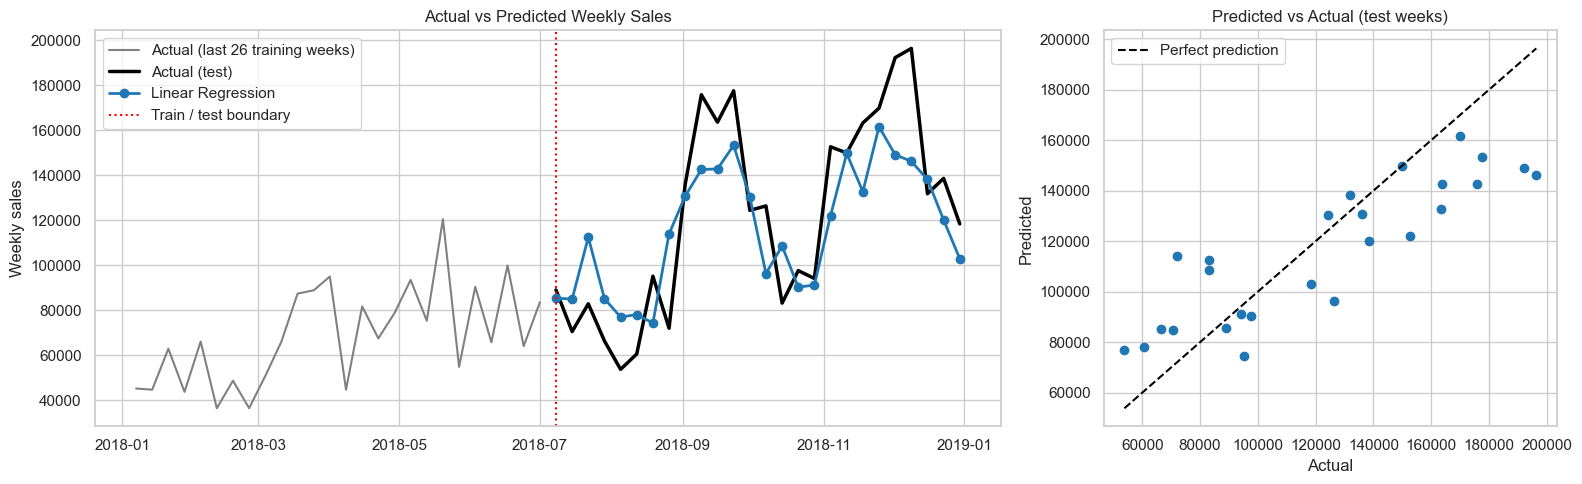


=== MONTHLY TOTALS (negative % = under-predicted) ===


,weeks,actual,predicted,pct_error
week_end,,,,
7,4,309109,368201.0,19.1
8,4,281743,343576.0,21.9
9,5,777318,699853.0,-10.0
10,4,401486,386584.0,-3.7
11,4,635639,566138.0,-10.9
12,5,777428,656589.0,-15.5


Total over 26 weeks: actual 3,182,723, predicted 3,020,941, difference -5.1%


In [19]:
# Step 10: Actual vs predicted for the chosen model

lr_pred = model_preds["Linear Regression"]
baseline = (X_test["lag_52"] * growth)

comp = pd.DataFrame({
    "actual": y_test,
    "predicted": lr_pred.round(),
    "baseline": baseline.round(),
})
comp["error"] = comp["predicted"] - comp["actual"]          # negative = under-predicted
comp["pct_error"] = (comp["error"] / comp["actual"] * 100).round(1)
display(comp)

# Headline numbers in context
mean_sales = y_test.mean()
print(f"Mean weekly sales (test): {mean_sales:,.0f}")
print(f"MAE  = {mean_absolute_error(y_test, lr_pred):,.0f}  ({mean_absolute_error(y_test, lr_pred)/mean_sales:.1%} of mean weekly sales)")
print(f"Bias = {(lr_pred - y_test).mean():,.0f}  ({(lr_pred - y_test).mean()/mean_sales:.1%} of mean weekly sales)")
within_20 = (comp["pct_error"].abs() <= 20).sum()
print(f"Weeks within +/-20% of actual: {within_20} of {len(comp)}")

# Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
ctx = y_train.iloc[-26:]
ax.plot(ctx.index, ctx, color="gray", label="Actual (last 26 training weeks)")
ax.plot(y_test.index, y_test, color="black", linewidth=2.5, label="Actual (test)")
ax.plot(lr_pred.index, lr_pred, color="tab:blue", linewidth=2, marker="o", label="Linear Regression")
ax.axvline(y_test.index.min(), color="red", linestyle=":", label="Train / test boundary")
ax.set_title("Actual vs Predicted Weekly Sales")
ax.set_ylabel("Weekly sales")
ax.legend()

ax = axes[1]
lo, hi = min(y_test.min(), lr_pred.min()), max(y_test.max(), lr_pred.max())
ax.scatter(y_test, lr_pred, color="tab:blue")
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", label="Perfect prediction")
ax.set_xlabel("Actual")
ax.set_ylabel("Predicted")
ax.set_title("Predicted vs Actual (test weeks)")
ax.legend()

plt.tight_layout()
plt.show()

# Monthly totals (weeks are assigned to the month in which they END)
monthly_cmp = comp.groupby(comp.index.month).agg(
    weeks=("actual", "count"),
    actual=("actual", "sum"),
    predicted=("predicted", "sum"))
monthly_cmp["pct_error"] = ((monthly_cmp["predicted"] - monthly_cmp["actual"])
                            / monthly_cmp["actual"] * 100).round(1)
print("\n=== MONTHLY TOTALS (negative % = under-predicted) ===")
display(monthly_cmp)

tot_a, tot_p = comp["actual"].sum(), comp["predicted"].sum()
print(f"Total over 26 weeks: actual {tot_a:,.0f}, predicted {tot_p:,.0f}, difference {(tot_p - tot_a)/tot_a:.1%}")

## Step 11: Recursive 4-week forecast
- Recursive forecast function (checked against Step 8)
- Backtest of 4-week recursive forecasts vs baselines
- Final forecast, refit on all 156 modelling weeks

Recursive function check passed (matches the Step 8 prediction for 2018-07-08).

=== BACKTEST: MAE by forecast horizon (weeks ahead) ===


,origins,LR_MAE,Baseline_MAE,Naive_MAE,LR_bias
h,,,,,
1,23,21198.0,24109.0,21022.0,-5834.0
2,23,22209.0,23563.0,31006.0,-6501.0
3,23,24870.0,23820.0,44131.0,-9085.0
4,23,24341.0,21563.0,50409.0,-11284.0



Last 4 actual weeks:
week_end
2018-12-09    196342
2018-12-16    131804
2018-12-23    138622
2018-12-30    118414
Freq: W-SUN

=== 4-WEEK FORECAST ===


,LinReg_forecast,typical_miss_+/-,Baseline_forecast,same_week_2018_actual,LinReg_vs_2018_%
2019-01-06,88096.0,21198.0,58262.0,45321,94.4
2019-01-13,83569.0,22209.0,57589.0,44797,86.6
2019-01-20,84898.0,24870.0,80979.0,62992,34.8
2019-01-27,79577.0,24341.0,56331.0,43819,81.6


4-week total  LinReg: 336,140 | Baseline: 253,161 | Same weeks 2018: 196,929


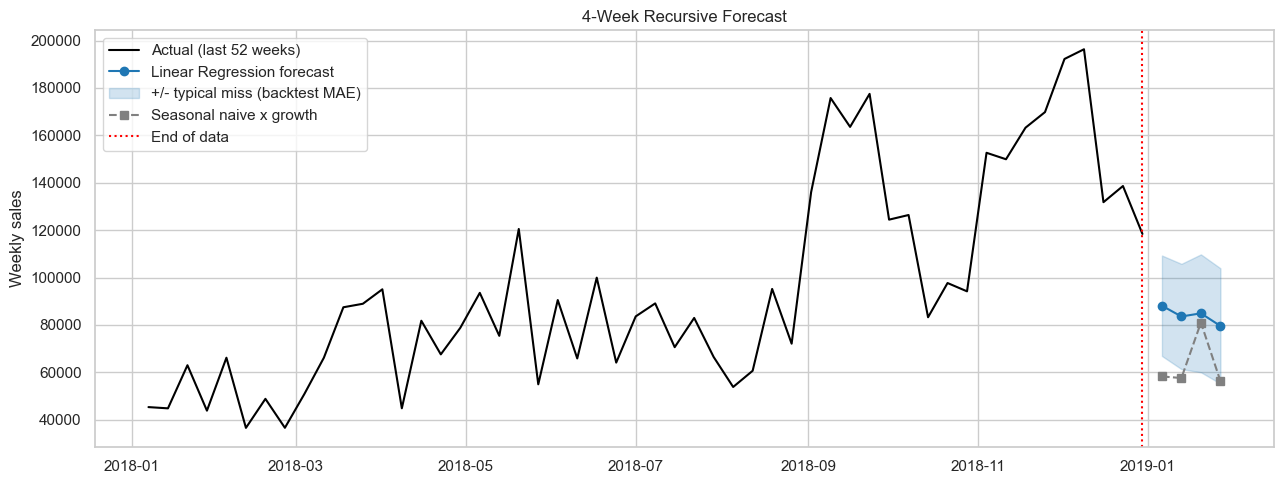

In [20]:
# Step 11: Recursive forecasting

def recursive_forecast(model, history, horizon=4):
    """history: weekly sales ending at the origin week. Each prediction is appended
    to the history, so later weeks use earlier predictions as their lags."""
    hist = history.copy()
    origin = hist.index[-1]
    t_origin = data.loc[origin, "t"]
    preds, dates = [], []
    for h in range(1, horizon + 1):
        date = origin + pd.Timedelta(weeks=h)
        doy = date.dayofyear
        row = pd.DataFrame([[
            t_origin + h,
            np.sin(2 * np.pi * doy / 365.25),
            np.cos(2 * np.pi * doy / 365.25),
            hist.iloc[-1], hist.iloc[-2], hist.iloc[-4], hist.iloc[-52],
            hist.iloc[-4:].mean(),
        ]], columns=feature_cols)
        pred = float(model.predict(row)[0])
        preds.append(pred)
        dates.append(date)
        hist = pd.concat([hist, pd.Series([pred], index=[date])])
    return pd.Series(preds, index=dates)

def seasonal_growth_forecast(history, horizon=4):
    """Same week last year x growth, using only data up to the origin."""
    g = history.iloc[-52:].sum() / history.iloc[-104:-52].sum()
    idx = [history.index[-1] + pd.Timedelta(weeks=h) for h in range(1, horizon + 1)]
    return pd.Series([history.iloc[-(53 - h)] * g for h in range(1, horizon + 1)], index=idx)

# 1. Check the function against Step 8 (first test week, 2018-07-08)
lr_130 = models["Linear Regression"]          # fitted on the 130 training weeks
chk = recursive_forecast(lr_130, data["sales"].loc[:train.index.max()], 1)
assert np.isclose(chk.iloc[0], model_preds["Linear Regression"].iloc[0])
print("Recursive function check passed (matches the Step 8 prediction for 2018-07-08).")

# 2. Backtest: 4-week recursive forecasts from each origin in the test period
origins = model_df.index[len(train) - 1 : len(model_df) - 4]
rows = []
for origin in origins:
    hist = data["sales"].loc[:origin]
    fc = recursive_forecast(lr_130, hist, 4)
    bl = seasonal_growth_forecast(hist, 4)
    actual = data["sales"].reindex(fc.index).values
    for h in range(4):
        rows.append({"h": h + 1, "actual": actual[h], "LR": fc.iloc[h],
                     "Baseline": bl.iloc[h], "Naive": hist.iloc[-1]})
bt = pd.DataFrame(rows)
for m in ["LR", "Baseline", "Naive"]:
    bt[f"{m}_abs"] = (bt["actual"] - bt[m]).abs()
    bt[f"{m}_err"] = bt[m] - bt["actual"]

summary = bt.groupby("h").agg(
    origins=("actual", "count"),
    LR_MAE=("LR_abs", "mean"),
    Baseline_MAE=("Baseline_abs", "mean"),
    Naive_MAE=("Naive_abs", "mean"),
    LR_bias=("LR_err", "mean")).round()
print("\n=== BACKTEST: MAE by forecast horizon (weeks ahead) ===")
display(summary)

# 3. Final forecast: refit on all 156 modelling weeks, forecast beyond 2018-12-30
final_model = LinearRegression().fit(model_df[feature_cols], model_df["sales"])
hist_all = data["sales"]
fc_lr = recursive_forecast(final_model, hist_all, 4)
fc_base = seasonal_growth_forecast(hist_all, 4)
last_year = pd.Series([hist_all.iloc[-(53 - h)] for h in range(1, 5)], index=fc_lr.index)

print("\nLast 4 actual weeks:")
print(hist_all.tail(4).to_string())

future = pd.DataFrame({
    "LinReg_forecast": fc_lr.round(),
    "typical_miss_+/-": summary["LR_MAE"].values,
    "Baseline_forecast": fc_base.round(),
    "same_week_2018_actual": last_year,
})
future["LinReg_vs_2018_%"] = ((fc_lr / last_year - 1) * 100).round(1)
print("\n=== 4-WEEK FORECAST ===")
display(future)
print(f"4-week total  LinReg: {fc_lr.sum():,.0f} | Baseline: {fc_base.sum():,.0f} | Same weeks 2018: {last_year.sum():,.0f}")

# 4. Chart
miss = summary["LR_MAE"].values
ctx = hist_all.iloc[-52:]
plt.figure(figsize=(13, 5))
plt.plot(ctx.index, ctx, color="black", label="Actual (last 52 weeks)")
plt.plot(fc_lr.index, fc_lr, "o-", color="tab:blue", label="Linear Regression forecast")
plt.fill_between(fc_lr.index, fc_lr - miss, fc_lr + miss, color="tab:blue", alpha=0.2,
                 label="+/- typical miss (backtest MAE)")
plt.plot(fc_base.index, fc_base, "s--", color="gray", label="Seasonal naive x growth")
plt.axvline(hist_all.index[-1], color="red", linestyle=":", label="End of data")
plt.title("4-Week Recursive Forecast")
plt.ylabel("Weekly sales")
plt.legend()
plt.tight_layout()
plt.show()